# AIDA 2156 Project Exercise 02 – Completeness Patterns

**Question:** Which intake fields are missing, and how do missing-information rates vary by task type and intake channel?

This notebook uses the original synthetic `requests.csv` and `assessments.csv` files from AIDA 1141 Exercise 02. It explores designed intake gaps; the deliberately corrupted records were checked separately in AIDA 1141 Exercise 03.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("../../../AIDA-1141/project-labs/02-synthetic-request-records/data")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# Only truly empty cells become missing (NaN); the text "not_applicable" and the number 0 stay as values
requests = pd.read_csv(DATA_DIR / "requests.csv", keep_default_na=False, na_values=[""])
assessments = pd.read_csv(DATA_DIR / "assessments.csv", keep_default_na=False, na_values=[""])
print(f"Loaded {len(requests):,} requests and {len(assessments):,} assessments")

Loaded 2,064 requests and 2,579 assessments


## Blank, not applicable, and zero

A blank required intake field represents missing information. An empty requester comment is acceptable because comments are optional. The value `not_applicable` means an equipment item is not required for that task, while a numeric zero represents a measured value rather than missing data.

In [2]:
summary = pd.DataFrame({
    "blank": requests.isna().sum(),
    "not_applicable": (requests == "not_applicable").sum(),
})
summary["blank_%"] = (summary["blank"] / len(requests) * 100).round(1)
summary = summary[(summary["blank"] > 0) | (summary["not_applicable"] > 0)]

# blank_% uses all requests; for equipment_item, the fairer denominator is equipment requests only
equipment = requests["task_type"].eq("equipment_setup")
print("Missing equipment items among equipment requests:",
      f"{requests.loc[equipment, 'equipment_item'].isna().mean():.1%}")
summary

Missing equipment items among equipment requests: 1.3%


,blank,not_applicable,blank_%
submitted_hiring_department,80,0,3.9
submitted_start_date,67,0,3.2
equipment_item,4,1688,0.2
requester_comment,1508,0,73.1


In [3]:
# Missing intake information: a blank submitted start date or department, or a blank item on an equipment task
is_equipment = requests["task_type"] == "equipment_setup"
missing = pd.DataFrame({
    "start_date": requests["submitted_start_date"].isna(),
    "department": requests["submitted_hiring_department"].isna(),
    "equipment_item": requests["equipment_item"].isna() & is_equipment,
})
missing["any_missing"] = missing.any(axis=1)

def missing_by(group):
    counts = missing.groupby(requests[group]).sum()
    counts.insert(0, "requests", requests[group].value_counts())
    counts["any_missing_%"] = (counts["any_missing"] / counts["requests"] * 100).round(1)
    return counts

by_channel = missing_by("intake_channel").reindex(["web_form", "email", "phone"])
by_task = missing_by("task_type").sort_values("requests", ascending=False)
pd.concat({"by intake channel": by_channel, "by task type": by_task}).to_csv(OUTPUT_DIR / "missingness_by_group.csv")
display(by_channel)
display(by_task)

,requests,start_date,department,equipment_item,any_missing,any_missing_%
intake_channel,,,,,,
web_form,1096,18,24,0,42,3.8
email,661,31,41,2,74,11.2
phone,307,18,15,2,35,11.4


,requests,start_date,department,equipment_item,any_missing,any_missing_%
task_type,,,,,,
payroll_setup,500,15,20,0,35,7.0
system_access,500,13,22,0,35,7.0
orientation_scheduling,426,17,14,0,31,7.3
workplace_access,322,17,11,0,28,8.7
equipment_setup,316,5,13,4,22,7.0


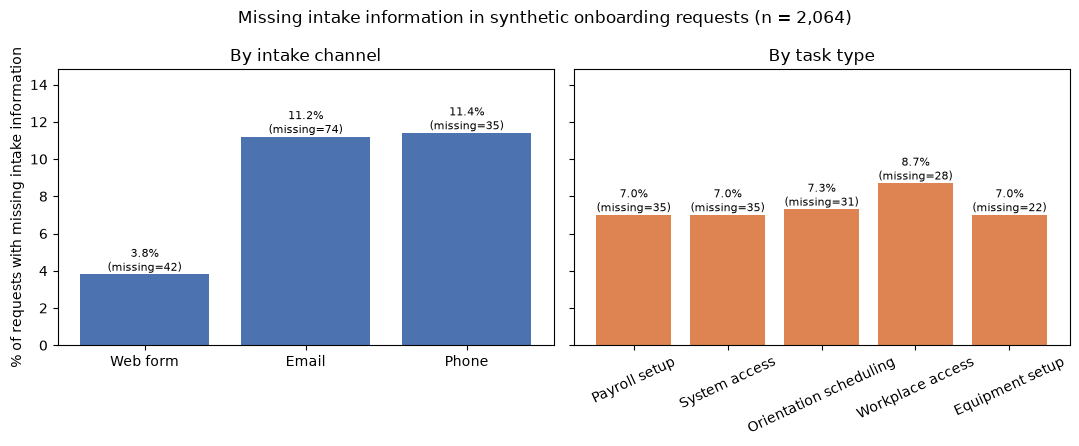

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
axes[0].bar([c.replace("_", " ").capitalize() for c in by_channel.index], by_channel["any_missing_%"], color="#4C72B0")
axes[0].set_title("By intake channel")
axes[1].bar([t.replace("_", " ").capitalize() for t in by_task.index], by_task["any_missing_%"], color="#DD8452")
axes[1].set_title("By task type")
axes[1].tick_params(axis="x", rotation=25)
for ax, data in [(axes[0], by_channel), (axes[1], by_task)]:
    for i, (pct, n) in enumerate(zip(data["any_missing_%"], data["any_missing"])):
        ax.text(i, pct + 0.2, f"{pct}%\n(missing={n})", ha="center", fontsize=8)
axes[0].set_ylabel("% of requests with missing intake information")
axes[0].set_ylim(0, max(by_channel["any_missing_%"].max(), by_task["any_missing_%"].max()) * 1.3)  # room for labels
fig.suptitle(f"Missing intake information in synthetic onboarding requests (n = {len(requests):,})")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "missingness_plot.png", dpi=150)
plt.show()

## What the table and chart show

Submitted hiring departments are missing in 80 requests (3.9%), and submitted start dates are missing in 67 (3.2%). Four equipment requests have a missing item, representing 1.3% of the 316 equipment requests, or 0.2% of all requests. Among non-equipment requests, 1,688 contain `not_applicable`, while 60 contain an equipment item as a designed conflict.

Missing-information rates vary more across intake channels than across task types in this generated dataset. Web forms have a rate of 3.8%, compared with 11.2% for email and 11.4% for phone. Task-type rates range from 7.0% to 8.7%.

Each request is counted once in `any_missing`, even if several required fields are blank. The chart shows each group’s percentage, with labels giving the number of requests missing information. These patterns reflect the generator’s settings, not real HR intake behaviour. Optional comments are blank in 1,508 requests (73.1%) and are excluded from the required-information measure.

In [5]:
numeric = ["business_days_until_start", "business_days_in_current_status", "team_open_workload"]
zeros_vs_blanks = pd.DataFrame({
    "blank": assessments[numeric].isna().sum(),
    "zero": (assessments[numeric] == 0).sum(),
    "negative": (assessments[numeric] < 0).sum(),
})
zeros_vs_blanks

,blank,zero,negative
business_days_until_start,0,28,35
business_days_in_current_status,0,2064,0
team_open_workload,0,10,0


## What the zeros mean

None of the three assessment fields has missing values. Time in the current status is zero for 2,064 assessments because checkpoint 1 occurs when the request enters its current open status.

Days until start is zero for 28 assessments made on the start date and negative for 35 made afterward. Team workload is zero for 10 assessments, meaning the responsible team had no assigned, unfinished tasks at that moment. These values are retained because they describe the workflow rather than missing information.

## Handling choices

Submitted blanks are kept as missing, without imputation, so the analysis preserves intake completeness. `not_applicable` remains a valid category, and numeric zeros and negative days until start are retained.

Confirmed start dates and hiring departments can support later analysis, but they do not replace submitted values here. This exercise examines the information provided when requests arrive, rather than the information available after clarification.

## Sample size and limitations

The 2,064 requests support descriptive comparisons within this synthetic dataset. Missing-information counts range from 22 to 74 across the groups shown, so small differences between task types should not be treated as evidence of a meaningful relationship without further analysis.

The records were generated using invented assumptions, including different missing-information probabilities by intake channel. The results describe this simulation and cannot establish completeness patterns in a real HR department.